## Factors Associated with Vessel Movement (Flag 16)

### Dataset Overview
A constructed Danish AIS-style case west of Jutland containing 94 complete trajectories from 57 vessels. Ordered points include speed, COG, heading, and navigation status; a vessel table supplies dimensions and type, while a separate coastline reference supports nearshore analysis.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Find what factors influence vessel movements in the sea area within the time period.

Role: Maritime traffic analyst


Category: vessel dimensions, draught, type, and movement characteristics

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How is vessel size, considering both length and width, associated with the consistency between COG and heading?

#### Analysis action

Link both vessel dimensions to trajectory points, calculate length × width, and compare it with the frequency of circular COG–heading gaps over 5°.

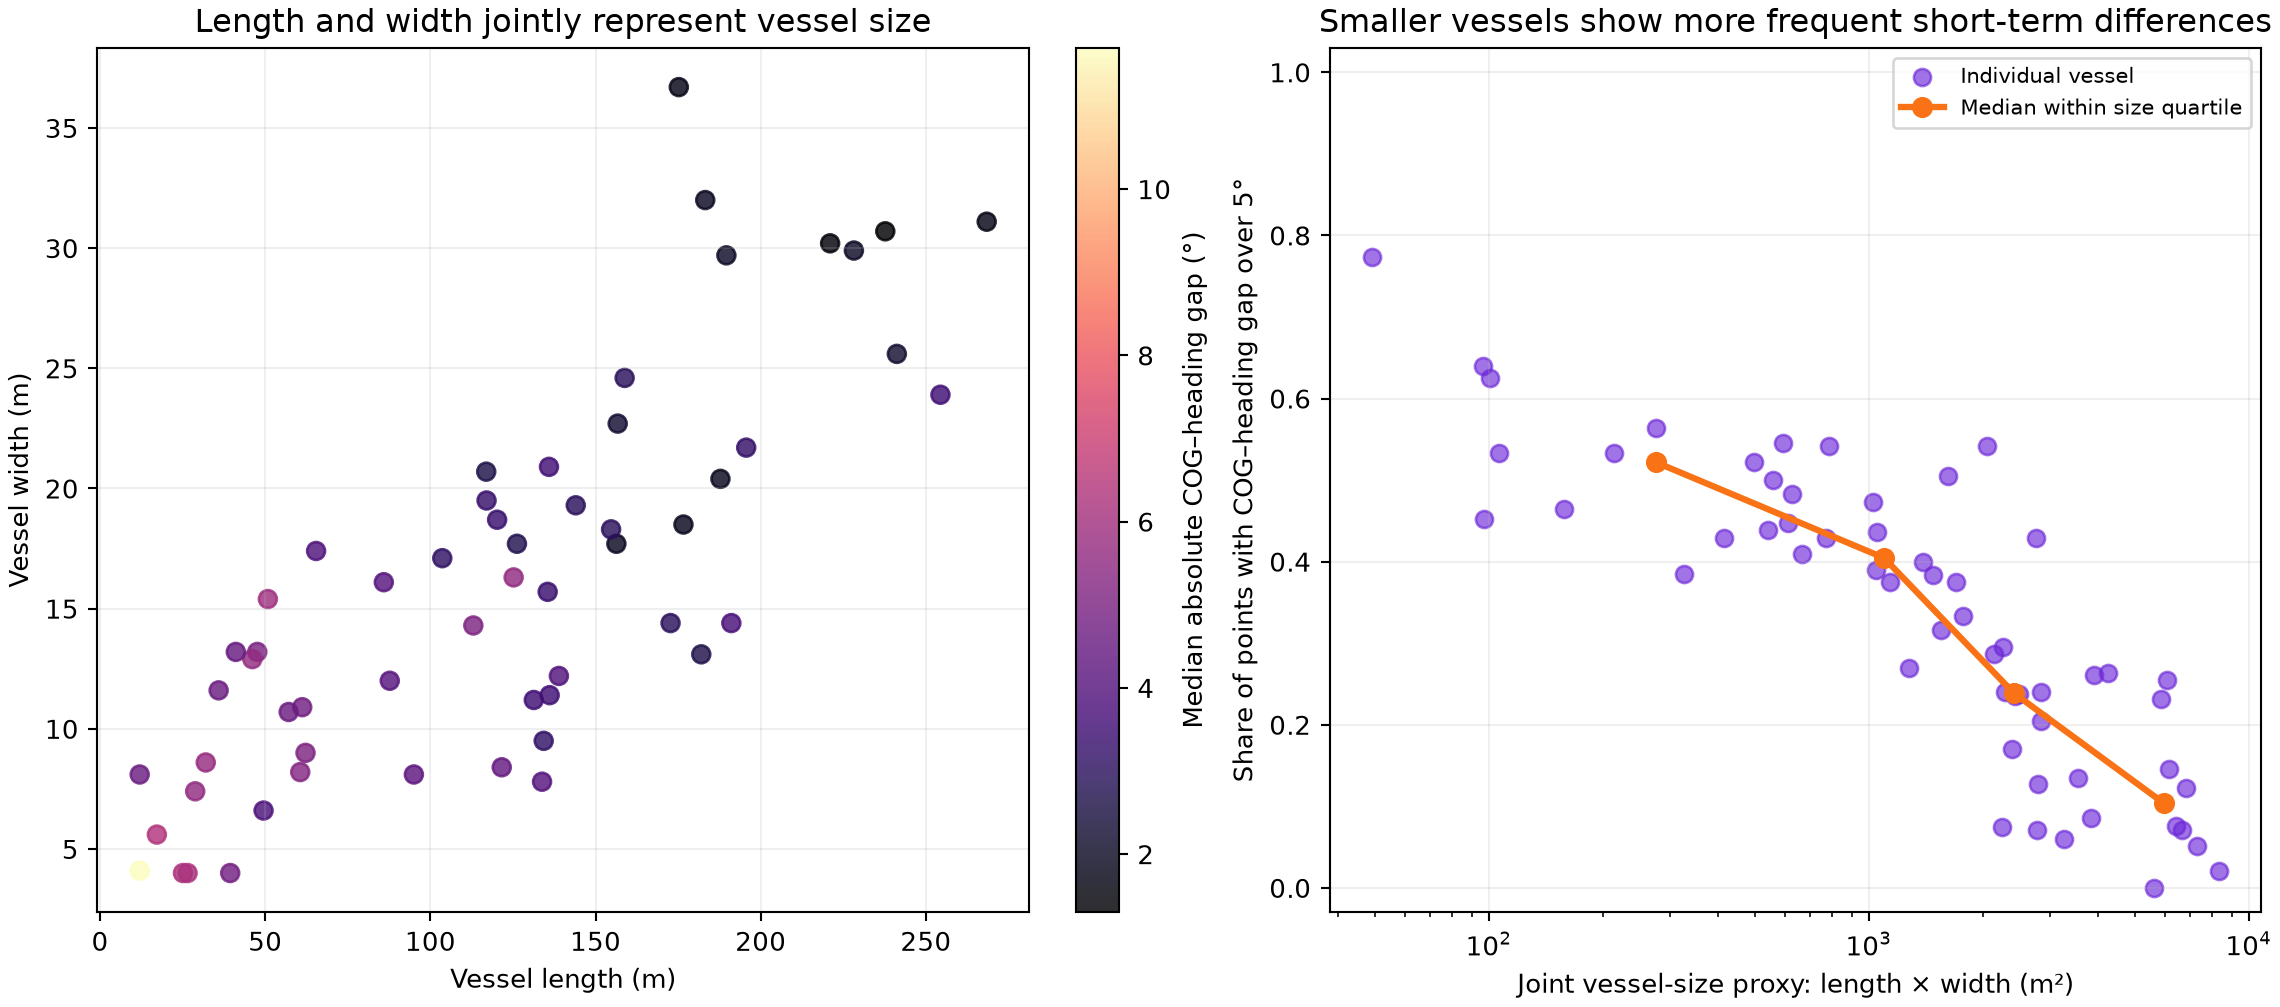

In [ ]:
import pandas as pd
points=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); vessels['footprint_proxy_m2']=vessels.length_m*vessels.width_m; df=points.merge(vessels,on='vessel_id'); df['gap']=abs((df.heading-df.cog+180)%360-180); print(df.groupby('vessel_id').agg(footprint_proxy_m2=('footprint_proxy_m2','first'),gap_over_5_share=('gap',lambda x:(x>5).mean())).describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/vessel_size_heading_cog_consistency.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "vessel_size_heading_cog_relationship",
  "insight": "Larger vessel size is associated with greater consistency between COG and heading, while smaller vessels show more frequent short-term differences.",
  "insight_value": {
    "vessel_size_proxy": "length_m × width_m",
    "size_proxy_tertile_cutoffs_m2": [
      941.7,
      2575.2
    ],
    "median_heading_cog_gap_deg": {
      "lower_size_tertile": 5.1,
      "upper_size_tertile": 2.12
    },
    "median_gap_over_5_share": {
      "lower_size_tertile": 0.5,
      "upper_size_tertile": 0.122
    }
  },
  "plot": {
    "plot_type": "length_width_and_short_term_difference_frequency_scatter",
    "title": "Vessel Size and COG–Heading Consistency",
    "file": "visualizations/vessel_size_heading_cog_consistency.png",
    "description": "The left panel shows both vessel dimensions; the right directly plots each vessel's length × width proxy against the share of its trajectory points whose absolute COG–heading gap exceeds 5°, with quartile medians showing how frequently short-term differences occur."
  },
  "question": "How is vessel size, considering both length and width, associated with the consistency between COG and heading?",
  "actionable_insight": "Link both vessel dimensions to trajectory points, calculate length × width, and compare it with the frequency of circular COG–heading gaps over 5°.",
  "code": "import pandas as pd\npoints=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); vessels['footprint_proxy_m2']=vessels.length_m*vessels.width_m; df=points.merge(vessels,on='vessel_id'); df['gap']=abs((df.heading-df.cog+180)%360-180); print(df.groupby('vessel_id').agg(footprint_proxy_m2=('footprint_proxy_m2','first'),gap_over_5_share=('gap',lambda x:(x>5).mean())).describe())",
  "insight_type": "factor_relationship",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_length",
    "vessel_width",
    "heading",
    "course_over_ground",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 2**: How does vessel draught relate to route distance from the coast?

#### Analysis action

Measure each trajectory's distance to the supplied coast reference and compare it with linked vessel draught.

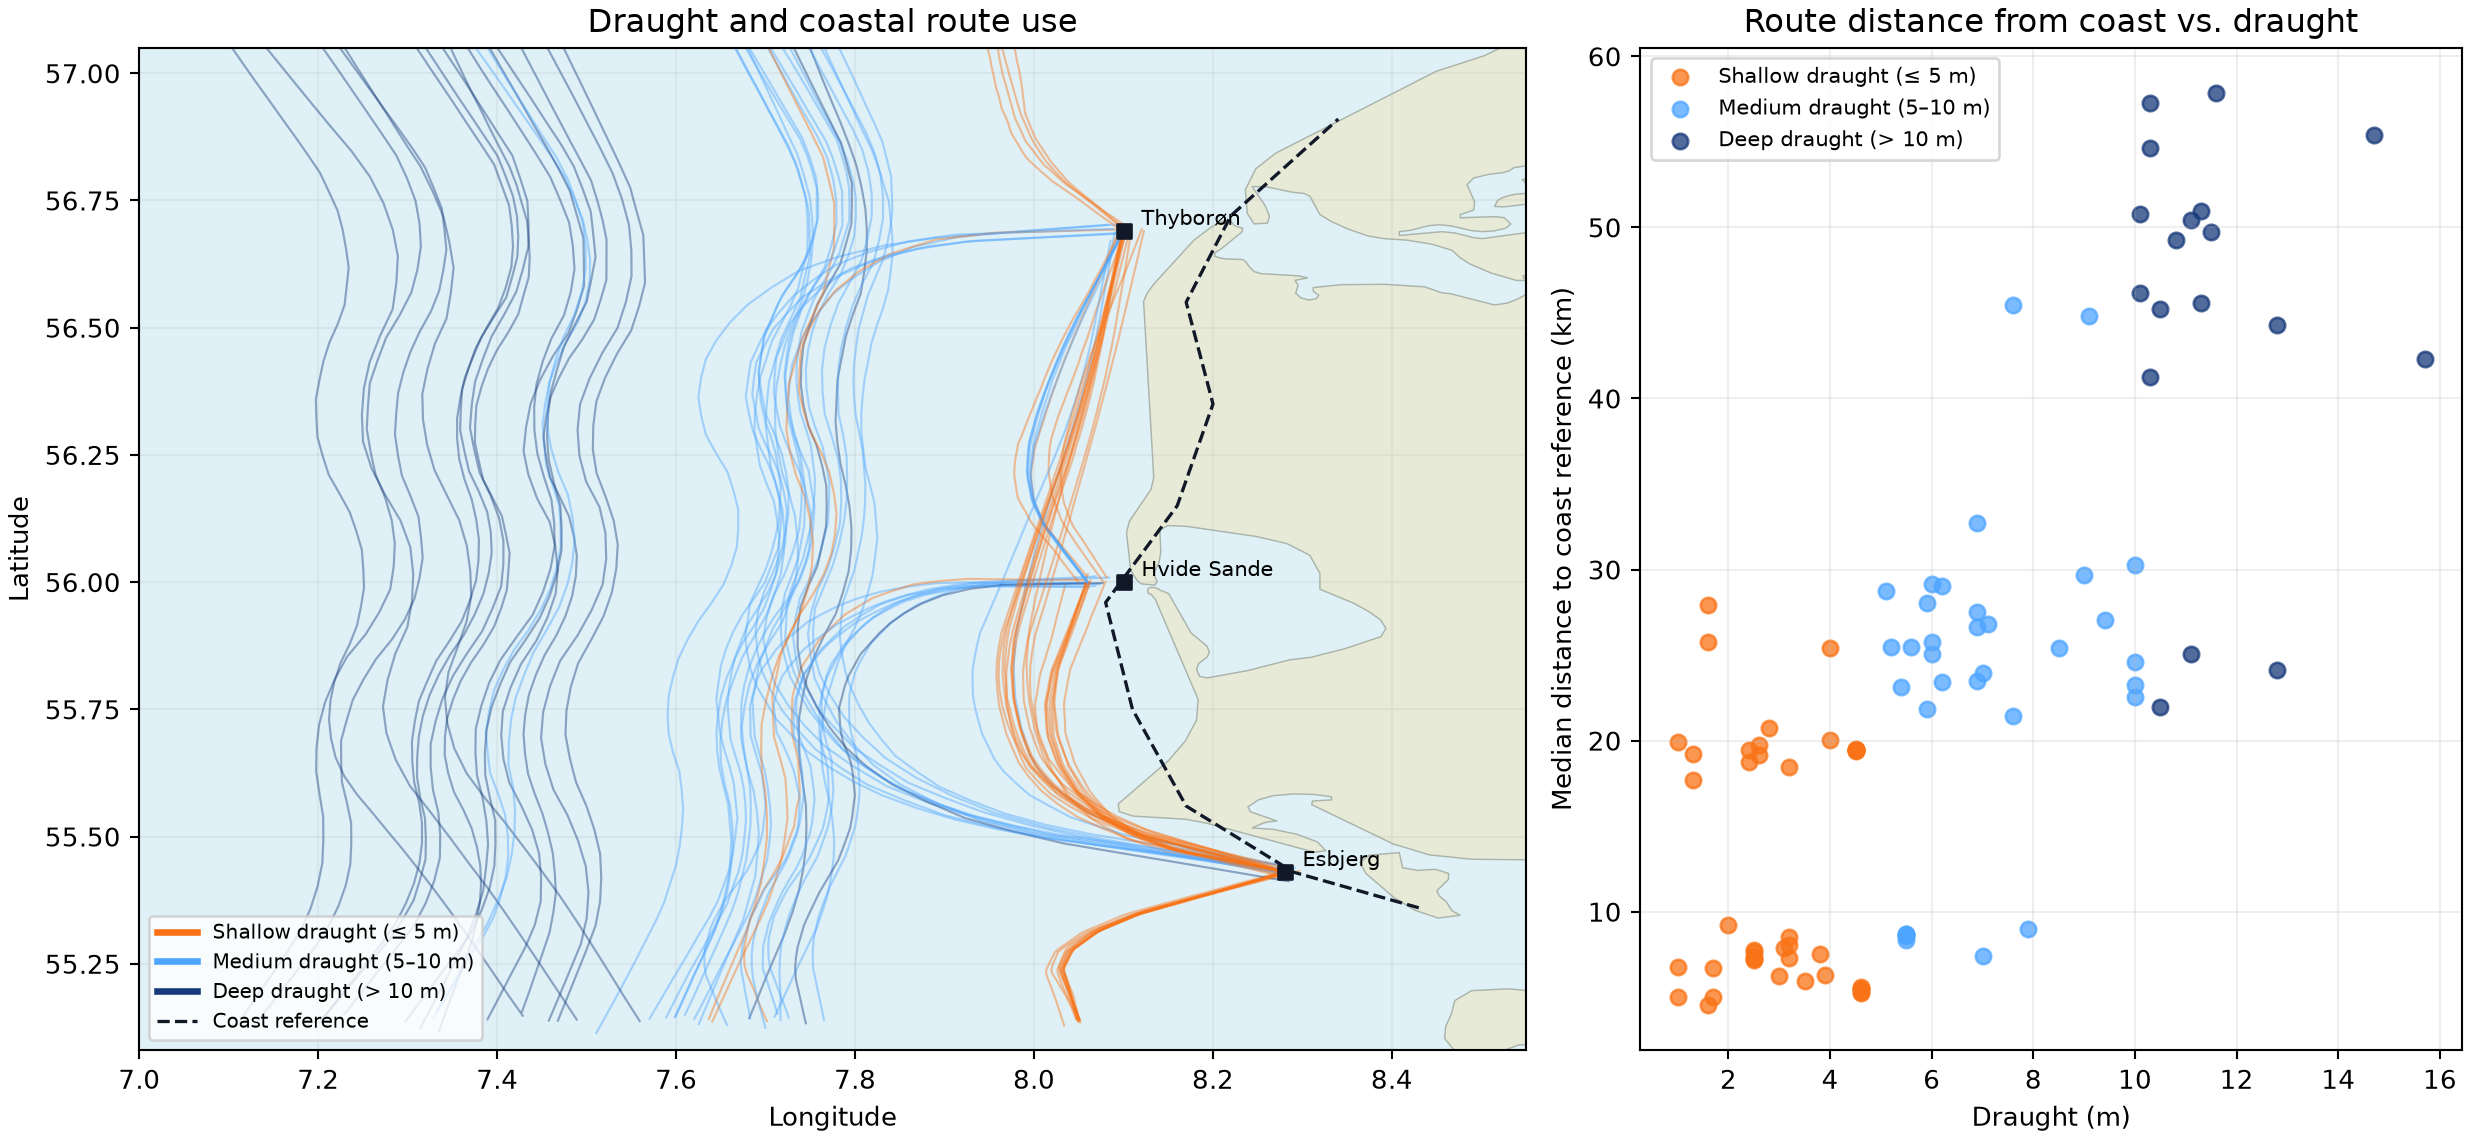

In [ ]:
import pandas as pd
from pathlib import Path
points=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); coast=pd.read_csv(Path('coastline_reference.csv')); print(vessels.draught_m.describe()); print(coast.head())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/draught_and_coastal_routes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "draught_coastal_route_relationship",
  "insight": "Draught affects vessel routes, with shallow-draught vessels travelling closer to and sometimes along the coast.",
  "insight_value": {
    "median_coast_distance_km": {
      "shallow_draught_at_most_5m": 7.97,
      "deep_draught_over_10m": 47.71
    }
  },
  "plot": {
    "plot_type": "draught_route_map_and_scatter",
    "title": "Draught and Coastal Route Use",
    "file": "visualizations/draught_and_coastal_routes.png",
    "description": "Trajectory geometry and continuous draught are compared with distance from the supplied west-Jutland coast reference."
  },
  "question": "How does vessel draught relate to route distance from the coast?",
  "actionable_insight": "Measure each trajectory's distance to the supplied coast reference and compare it with linked vessel draught.",
  "code": "import pandas as pd\nfrom pathlib import Path\npoints=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); coast=pd.read_csv(Path('coastline_reference.csv')); print(vessels.draught_m.describe()); print(coast.head())",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "draught",
    "gps_position",
    "coast_reference",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: Which vessel types are associated with low-speed movements and recurrent routes?

#### Analysis action

Compare trajectory mean speed and repeated-path dispersion by ship type while retaining non-ferry low-speed cases.

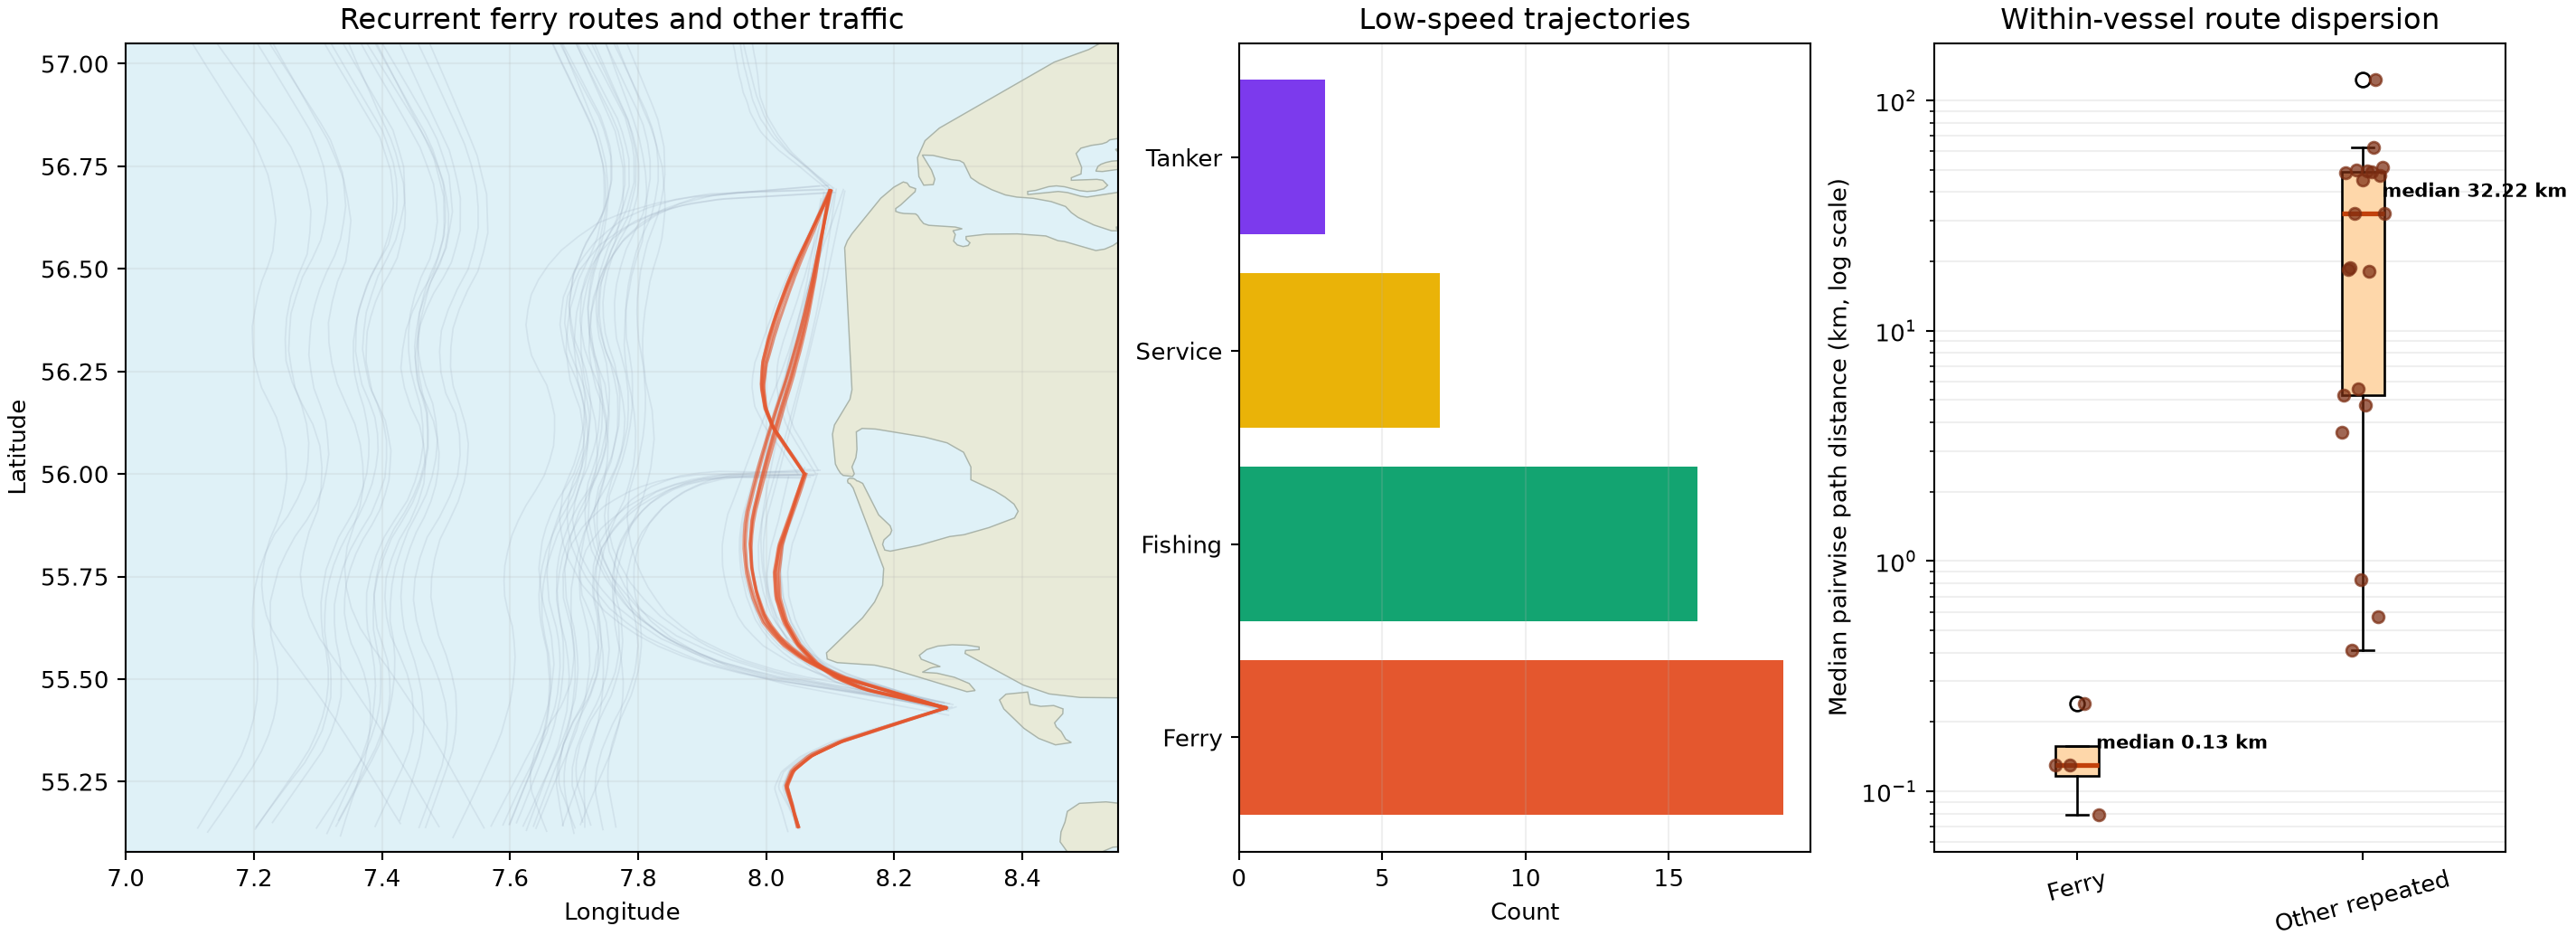

In [ ]:
import pandas as pd
points=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); df=points.merge(vessels,on='vessel_id'); print(df.groupby(['ship_type','trajectory_id']).sog_knots.mean().groupby(level=0).describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/ferry_low_speed_recurrence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "ferry_speed_route_recurrence_relationship",
  "insight": "Low-speed movements and recurrent routes are often associated with ferry vessels.",
  "insight_value": {
    "low_speed_trajectory_counts": {
      "Ferry": 19,
      "Fishing": 16,
      "Service": 7,
      "Tanker": 3
    },
    "median_route_dispersion_km": {
      "ferry": 0.13,
      "other_repeated_vessels": 32.223
    }
  },
  "plot": {
    "plot_type": "map_bar_and_recurrence_distribution",
    "title": "Ferry Low-Speed and Recurrent Movement",
    "file": "visualizations/ferry_low_speed_recurrence.png",
    "description": "The map, low-speed counts, and within-vessel path dispersion jointly show the association without claiming that every low-speed movement is a ferry."
  },
  "question": "Which vessel types are associated with low-speed movements and recurrent routes?",
  "actionable_insight": "Compare trajectory mean speed and repeated-path dispersion by ship type while retaining non-ferry low-speed cases.",
  "code": "import pandas as pd\npoints=pd.read_csv(dataset_path); vessels=pd.read_csv(user_dataset_path); df=points.merge(vessels,on='vessel_id'); print(df.groupby(['ship_type','trajectory_id']).sog_knots.mean().groupby(level=0).describe())",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "ship_type",
    "gps_position",
    "point_speed",
    "trajectory_timestamp"
  ]
}

### Summary of Findings (Flag 16)

Larger vessel size is associated with greater consistency between COG and heading, while smaller vessels show more frequent short-term differences. Draught affects vessel routes, with shallow-draught vessels travelling closer to and sometimes along the coast. Low-speed movements and recurrent routes are often associated with ferry vessels.